# Phase 1: Environment Setup & Core Imports
Setting up the environment variables, LangSmith tracing, and importing the required LangGraph and LangChain modules for the HR Copilot architecture.

In [32]:
import os
import re
import json
import pickle
import operator
import pandas as pd
from typing import TypedDict, Annotated, Sequence, Literal
from dotenv import load_dotenv

# LangChain & LangGraph Imports
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.messages import BaseMessage, SystemMessage, AIMessage, HumanMessage
from langchain_experimental.agents.agent_toolkits import create_pandas_dataframe_agent
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langchain.tools import tool

# Qdrant Vector Store Imports
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams

# Load Environment Variables (OpenAI & LangSmith)
load_dotenv()

# Initialize the core orchestrator LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Phase 2: Data Analyst Agent (System 2 Thinking)
This node handles macro-level dataset queries. It forces the Pandas agent to output interactive Plotly charts instead of static Matplotlib images by saving the artifacts to a JSON file.

In [34]:
# Load the dataset
df = pd.read_csv("../datasets/WA_Fn-UseC_-HR-Employee-Attrition.csv")

# Initialize Pandas Agent
analyst_agent = create_pandas_dataframe_agent(
    llm, 
    df, 
    verbose=True, 
    allow_dangerous_code=True, 
    agent_type="openai-tools"
)

def data_analyst_node(state):
    """Node responsible for querying aggregate trends in the dataset."""
    messages = state["messages"]
    user_prompt = messages[-1].content
    
    chart_instruction = """
    If the user asks to visualize, plot, or graph the data, you MUST use the `plotly.express` library. 
    Do NOT use matplotlib, seaborn, or plt.show(). You MUST save the Plotly figure to a file named 'interactive_chart.json' using `fig.write_json('interactive_chart.json')`.
    In your final response, explicitly state: "[CHART_GENERATED]" alongside your numerical findings.
    """
    
    combined_prompt = f"{user_prompt}\n\n{chart_instruction}"
    response = analyst_agent.invoke({"input": combined_prompt})
    
    return {"messages": [SystemMessage(content=f"Analyst Result: {response['output']}")]}

# Phase 3: ML Predictor & Mock HRIS Database Tools
Here we load the pre-trained Scikit-Learn models and SHAP explainers. We define two interconnected tools: one to run the prediction math, and another to autonomously fetch real employee data from the CSV file based on an Employee ID or Department Name.

In [36]:
# Load Pickled Assets
try:
    model = pickle.load(open('../models/model_2024_05_16.sav', 'rb'))
    encoders = pickle.load(open('../models/encoder_2024_05_16.sav', 'rb'))
    explainer = pickle.load(open('../models/explainer_2024_05_16.sav', 'rb'))
except Exception as e:
    print(f"Warning: Could not load pickled assets: {e}")
    model, encoders, explainer = None, {}, None

@tool
def predict_churn_probability(
    age_generation: str = 'Millennials', business_travel: str = 'Travel_Rarely', daily_rate: int = 800, 
    department: str = 'Research & Development', distance_from_home_category: str = 'Short Distance', 
    education: str = 'Bachelor', education_field: str = 'Life Sciences', environment_satisfaction: str = 'High', 
    gender: str = 'Male', job_involvement: str = 'High', job_level: int = 2, job_role: str = 'Sales Executive', 
    job_satisfaction: str = 'High', marital_status: str = 'Married', num_companies_worked: int = 1, 
    overtime_preference: int = 0, percent_salary_hike: int = 15, performance_rating: str = 'Excellent', 
    relationship_satisfaction: str = 'High', stock_option_level: int = 1, total_working_years: int = 10, 
    training_times_last_year: int = 2, work_life_balance: str = 'Good', years_at_company: int = 5, 
    years_in_current_role: int = 3, years_since_last_promotion: int = 1, years_with_curr_manager: int = 3
) -> str:
    """Evaluates retention risk and extracts key behavioral risk drivers for a specific employee."""
    
    def safe_int(val):
        return int(val[0]) if isinstance(val, list) and val else int(val)

    features = [
        'AgeGeneration', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHomeCategory',
        'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement',
        'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'NumCompaniesWorked',
        'Overtime_Preference', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
        'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
        'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
    ]
    values = [
        age_generation, business_travel, safe_int(daily_rate), department, distance_from_home_category,
        education, education_field, environment_satisfaction, gender, job_involvement,
        safe_int(job_level), job_role, job_satisfaction, marital_status, safe_int(num_companies_worked),
        safe_int(overtime_preference), safe_int(percent_salary_hike), performance_rating, relationship_satisfaction,
        safe_int(stock_option_level), safe_int(total_working_years), safe_int(training_times_last_year), work_life_balance,
        safe_int(years_at_company), safe_int(years_in_current_role), safe_int(years_since_last_promotion), safe_int(years_with_curr_manager)
    ]
    
    df_to_predict = pd.DataFrame(values, index=features).T
    for col in encoders.keys():
        if col not in ['Attrition', 'OverTime'] and col in df_to_predict.columns:
            val = df_to_predict[col].iloc[0]
            if val not in encoders[col].classes_: val = encoders[col].classes_[0]
            df_to_predict[col] = encoders[col].transform([val])[0]

    if model is not None:
        pred_proba = model.predict_proba(df_to_predict)
        active_proba, churn_proba = float(pred_proba[0][0]), float(pred_proba[0][1])
    else:
        churn_proba = 0.65 if safe_int(overtime_preference) == 1 or safe_int(years_at_company) > 5 else 0.25
        active_proba = 1.0 - churn_proba

    hr_feature_names = {
        'Overtime_Preference': 'Overtime Workload & Schedule', 'DailyRate': 'Daily Compensation Rate',
        'PercentSalaryHike': 'Recent Salary Increase History', 'TotalWorkingYears': 'Total Industry Experience',
        'YearsInCurrentRole': 'Tenure in Current Role', 'YearsAtCompany': 'Company Tenure',
        'JobSatisfaction': 'Reported Job Satisfaction', 'EnvironmentSatisfaction': 'Workplace Environment Satisfaction',
        'WorkLifeBalance': 'Work-Life Balance Rating', 'DistanceFromHomeCategory': 'Commute & Travel Distance',
        'BusinessTravel': 'Business Travel Frequency', 'TrainingTimesLastYear': 'Annual Training & Development',
        'YearsWithCurrManager': 'Tenure with Current Manager', 'YearsSinceLastPromotion': 'Time Since Last Promotion',
        'JobInvolvement': 'Job Involvement Level', 'StockOptionLevel': 'Stock Option & Equity Level',
        'NumCompaniesWorked': 'Prior Employer History'
    }

    drivers_text, chart_data = "", []
    if explainer is not None:
        try:
            shap_vals = explainer.shap_values(df_to_predict)
            s_vals = shap_vals[1][0] if isinstance(shap_vals, list) and len(shap_vals) > 1 else (shap_vals[0][0] if isinstance(shap_vals, list) else shap_vals[0])
            
            feature_imp = pd.DataFrame({'Feature': features, 'SHAP_Value': s_vals})
            feature_imp['Abs_SHAP'] = feature_imp['SHAP_Value'].abs()
            top_drivers = feature_imp.sort_values(by='Abs_SHAP', ascending=False).head(5)
            
            drivers_text = "\n**Key Behavioral Risk Drivers:**\n"
            for _, row in top_drivers.head(3).iterrows():
                clean_feat = hr_feature_names.get(row['Feature'], row['Feature'].replace('_', ' '))
                impact = "elevates retention risk" if row['SHAP_Value'] > 0 else "supports employee retention"
                drivers_text += f"- **{clean_feat}**: This factor {impact} for this employee.\n"
                
            for _, row in top_drivers.iterrows():
                clean_feat = hr_feature_names.get(row['Feature'], row['Feature'].replace('_', ' '))
                chart_data.append({"feature": clean_feat, "value": float(row['SHAP_Value'])})
            
            with open("shap_drivers.json", "w") as f:
                json.dump(chart_data, f)
        except Exception:
            pass

    return f"Retention Assessment: {active_proba * 100:.2f}% Probability of Retention, {churn_proba * 100:.2f}% Flight Risk.\n{drivers_text}"

@tool
def fetch_and_predict_employee(query: str) -> str:
    """HRIS Database API. Fetches data for an Employee ID (e.g., 101) or a Department (e.g., R&D, Sales) from the dataset."""
    try:
        hr_df = pd.read_csv("datasets/WA_Fn-UseC_-HR-Employee-Attrition.csv")
        query_lower = query.lower()
        
        numbers = re.findall(r'\d+', query_lower)
        target_row = None
        
        if numbers:
            subset = hr_df[hr_df['EmployeeNumber'] == int(numbers[0])]
            if not subset.empty: target_row = subset.iloc[0]
                
        if target_row is None:
            dept = 'Research & Development' if "research" in query_lower or "r&d" in query_lower else ('Sales' if "sales" in query_lower else ('Human Resources' if "hr" in query_lower else None))
            if dept:
                subset = hr_df[(hr_df['Department'] == dept) & (hr_df['YearsSinceLastPromotion'] >= 2)]
                target_row = subset.iloc[0] if not subset.empty else hr_df[hr_df['Department'] == dept].iloc[0]
                    
        if target_row is None:
            return f"HRIS Database Error: Could not find Employee ID or Department matching '{query}'."

        edu_map = {1: 'Below College', 2: 'College', 3: 'Bachelor', 4: 'Master', 5: 'Doctor'}
        sat_map = {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'}
        perf_map = {1: 'Low', 2: 'Good', 3: 'Excellent', 4: 'Outstanding'}
        wlb_map = {1: 'Bad', 2: 'Good', 3: 'Better', 4: 'Best'}
        
        age, dist = target_row['Age'], target_row['DistanceFromHome']
        gen = 'Millennials' if 28 <= age <= 43 else ('Gen X' if 44 <= age <= 59 else 'Gen Z')
        dist_cat = 'Short Distance' if dist <= 10 else ('Medium Distance' if dist <= 20 else 'Long Distance')

        kwargs = {
            'age_generation': gen, 'business_travel': target_row['BusinessTravel'], 'daily_rate': int(target_row['DailyRate']),
            'department': target_row['Department'], 'distance_from_home_category': dist_cat, 'education': edu_map.get(target_row['Education'], 'Bachelor'),
            'education_field': target_row['EducationField'], 'environment_satisfaction': sat_map.get(target_row['EnvironmentSatisfaction'], 'High'),
            'gender': target_row['Gender'], 'job_involvement': sat_map.get(target_row['JobInvolvement'], 'High'), 'job_level': int(target_row['JobLevel']),
            'job_role': target_row['JobRole'], 'job_satisfaction': sat_map.get(target_row['JobSatisfaction'], 'High'), 'marital_status': target_row['MaritalStatus'],
            'num_companies_worked': int(target_row['NumCompaniesWorked']), 'overtime_preference': 1 if target_row['OverTime'] == 'Yes' else 0,
            'percent_salary_hike': int(target_row['PercentSalaryHike']), 'performance_rating': perf_map.get(target_row['PerformanceRating'], 'Excellent'),
            'relationship_satisfaction': sat_map.get(target_row['RelationshipSatisfaction'], 'High'), 'stock_option_level': int(target_row['StockOptionLevel']),
            'total_working_years': int(target_row['TotalWorkingYears']), 'training_times_last_year': int(target_row['TrainingTimesLastYear']),
            'work_life_balance': wlb_map.get(target_row['WorkLifeBalance'], 'Good'), 'years_at_company': int(target_row['YearsAtCompany']),
            'years_in_current_role': int(target_row['YearsInCurrentRole']), 'years_since_last_promotion': int(target_row['YearsSinceLastPromotion']),
            'years_with_curr_manager': int(target_row['YearsWithCurrManager'])
        }
        
        prediction_result = predict_churn_probability.invoke(kwargs)
        return f"Database Lookup Success! Evaluated representative employee in {target_row['Department']} (Age {age}, Role: {target_row['JobRole']}).\n\n{prediction_result}"
    except Exception as e:
        return f"HRIS Database Error: {e}"

# Bind Tools & Define Node
predictor_llm = llm.bind_tools([predict_churn_probability, fetch_and_predict_employee])

def predictor_node(state):
    system_msg = SystemMessage(content="""You are an HR Predictive Analytics Assistant. 
    CRITICAL INSTRUCTION: When the user asks to predict churn, you MUST call a tool. 
    - If they provide specific employee traits, call `predict_churn_probability`.
    - If they provide an Employee ID or a Department Name, call `fetch_and_predict_employee`.
    Never refuse a prediction request.""")
    
    response = predictor_llm.invoke([system_msg] + state["messages"])
    
    if hasattr(response, "tool_calls") and response.tool_calls:
        tool_call = response.tool_calls[0]
        result = predict_churn_probability.invoke(tool_call["args"]) if tool_call["name"] == "predict_churn_probability" else fetch_and_predict_employee.invoke(tool_call["args"])
        return {"messages": [AIMessage(content=result)]}
    return {"messages": [response]}

/Users/cberches/Documents/GitHub/AttritionTest/capstone_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Phase 4: RAG Pipeline & Semantic Formatting
Initializes the Qdrant Vector Store to hold the DOLE-compliant HR playbook. The RAG node is designed to read the context, parse the prediction output without causing a memory leak, and format the response as either advice or a drafted email.

In [37]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
client = QdrantClient(":memory:")
client.create_collection(collection_name="hr_policies", vectors_config=VectorParams(size=1536, distance=Distance.COSINE))
vectorstore = QdrantVectorStore(client=client, collection_name="hr_policies", embedding=embeddings)

if os.path.exists("hr_retention_playbook.pdf"):
    loader = PyPDFLoader("hr_retention_playbook.pdf")
    splits = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150).split_documents(loader.load())
    vectorstore.add_documents(splits)

policy_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

def rag_node(state):
    messages = state["messages"]
    
    # 1. Clean Memory Extraction (Prevents hallucinating old predictions)
    prediction_output = ""
    last_msg = messages[-1]
    if isinstance(last_msg, AIMessage) and "Retention Assessment:" in last_msg.content:
        idx = last_msg.content.find("Retention Assessment:")
        if idx != -1: prediction_output = last_msg.content[idx:]
            
    # 2. Extract User Intent
    user_request = next((msg.content for msg in reversed(messages) if isinstance(msg, HumanMessage) or msg.type == 'human'), "")
    context = "\n\n".join(doc.page_content for doc in policy_retriever.invoke(user_request))
    
    # 3. Formulate RAG Output
    executive_hr_prompt = f"""You are a professional Senior HR Business Partner. Maintain an executive tone.
    CRITICAL FORMATTING RULES:
    1. If the user EXPLICITLY asks to "draft an email" or "write a memo", generate a ready-to-send professional email.
    2. If the user DOES NOT explicitly ask for an email, reply normally using clear bullet points.
    
    NEW retention risk assessment: {prediction_output}
    Company Policy Context: {context}
    Manager Request: {user_request}"""
    
    response = llm.invoke(executive_hr_prompt)
    final_content = f"**HR Copilot Analysis & Output:**\n\n{prediction_output}\n\n---\n\n{response.content}" if prediction_output else response.content
        
    return {"messages": [AIMessage(content=final_content)]}

# Phase 5: Agentic Semantic Router & Graph Compilation
The supervisor agent routes the user query using natural language understanding (System 1 thinking) to direct the flow to the Data Analyst, ML Predictor, or RAG nodes.

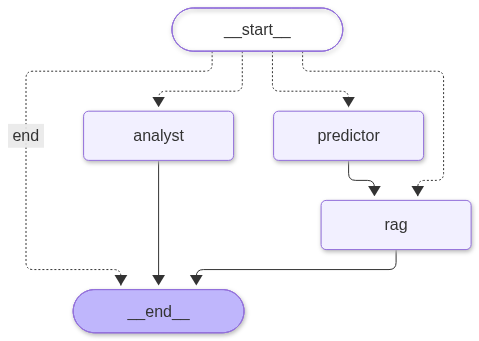

In [38]:
def supervisor_router(state) -> str:
    """Uses LLM semantic understanding to dynamically route the request without Pydantic serialization warnings."""
    last_message = state["messages"][-1].content
    
    router_prompt = f"""Analyze the user request and determine the single best routing destination.
    User Request: "{last_message}"
    
    - "analyst": Select ONLY if the user asks for dataset statistics, counts, averages, or to plot/chart data.
    - "predictor": Select ONLY if the user provides employee attributes OR an Employee ID to predict churn/flight risk.
    - "rag": Select ONLY if the user asks for general policies, retention strategies, or an email WITHOUT asking for a new prediction.
    - "predictor_then_rag": Select if they ask for a prediction AND ask for retention strategies or an email draft in the exact same prompt.
    
    Respond ONLY with the exact routing string. Do not include quotes."""
    
    try:
        decision = llm.invoke(router_prompt).content.strip().replace('"', '').lower()
        return decision if decision in ["analyst", "predictor", "rag", "predictor_then_rag"] else "rag"
    except Exception:
        return "rag"

# Graph Compilation
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], operator.add]

workflow = StateGraph(AgentState)
workflow.add_node("analyst", data_analyst_node)
workflow.add_node("predictor", predictor_node)
workflow.add_node("rag", rag_node)

workflow.set_conditional_entry_point(
    supervisor_router, 
    {"analyst": "analyst", "predictor": "predictor", "rag": "rag", "predictor_then_rag": "predictor", "end": END}
)
workflow.add_edge("predictor", "rag") 
workflow.add_edge("analyst", END)
workflow.add_edge("rag", END)

memory = MemorySaver()
hr_copilot = workflow.compile(checkpointer=memory)

# Optional: Draw the architecture
from IPython.display import Image, display
try: display(Image(hr_copilot.get_graph().draw_mermaid_png()))
except Exception: pass

# Phase 6: Experimentation & Testing Validations
Validating all node routing, data transformations, and generative outputs before integrating the agent into the Streamlit application.

In [39]:
# Initialize distinct threads to validate memory isolation
config_1 = {"configurable": {"thread_id": "eval_test_1"}}
config_2 = {"configurable": {"thread_id": "eval_test_2"}}

print("="*60)
print("TEST 1: ANALYST NODE (MACRO DATA EXPLORATION)")
print("="*60)
query_1 = "Plot a bar chart showing the average daily rate by department."
res_1 = hr_copilot.invoke({"messages": [HumanMessage(content=query_1)]}, config=config_1)
print(res_1["messages"][-1].content)
print(f"Artifact created? {os.path.exists('interactive_chart.json')}\n")

print("="*60)
print("TEST 2: PREDICTOR + RAG (HRIS MOCK & GENERATIVE ACTION)")
print("="*60)
query_2 = "Fetch the file for the Research and Development Team, run a churn prediction on them, and draft a retention strategy email to their manager."
res_2 = hr_copilot.invoke({"messages": [HumanMessage(content=query_2)]}, config=config_2)
print(res_2["messages"][-1].content)
print(f"\nArtifact created? {os.path.exists('shap_drivers.json')}")

TEST 1: ANALYST NODE (MACRO DATA EXPLORATION)


> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "import pandas as pd\nimport plotly.express as px\n\n# Assuming df is already defined as the DataFrame\n# Calculate the average DailyRate by Department\navg_daily_rate = df.groupby('Department')['DailyRate'].mean().reset_index()\n\n# Create a bar chart\nfig = px.bar(avg_daily_rate, x='Department', y='DailyRate', title='Average Daily Rate by Department')\n\n# Save the figure to a JSON file\nfig.write_json('interactive_chart.json')\n\navg_daily_rate"}`


               Department   DailyRate
0         Human Resources  751.539683
1  Research & Development  806.851197
2                   Sales  800.275785The average daily rate by department is as follows:

- Human Resources: 751.54
- Research & Development: 806.85
- Sales: 800.28

The bar chart has been generated and saved as 'interactive_chart.json'. 

[CHART_GENERATED]

> Finished chain.
Analyst Result: The a